# 2. Modelling, evaluation and serving

**Goal.** Predict, at purchase time, whether an order will be delivered late, and judge honestly what the model is worth.

Every section: **what and why**, **code**, **how to read the output**. Most heavy steps (cross-validation, the final test evaluation) are run by `python -m delivery.pipeline` and saved to `reports/`; this notebook runs the key pieces live and reads the saved results so it finishes in a minute or two.

| Section | Topic |
|---|---|
| 1 | The evaluation protocol and why it has gaps |
| 2 | Features, and a leakage check by brute force |
| 3 | Model selection by rolling cross-validation |
| 4 | The final model and what it learned |
| 5 | One evaluation on the test window |
| 6 | Calibration and drift |
| 7 | Would acting on the predictions pay? |
| 8 | Serving: from model to API |
| 9 | Summary and what not to claim |

## Setup

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src")); os.chdir(ROOT)
pd.set_option("display.width", 130, "display.max_columns", 30, "display.float_format", lambda v: f"{v:,.4f}")
FIG = ROOT / "reports" / "figures"
def show(name, width=760): display(Image(filename=str(FIG / name), width=width))

In [2]:
from delivery import config as C
from delivery.pipeline import prepare, C_REG
from delivery.features import FINAL_FEATURES, GROUPS, ALL_FEATURES
from delivery.split import make_splits, split_report
from delivery.modeling import fit_logreg
df, X, masks, enc, hol = prepare()
y = df["late"]
res = json.load(open("reports/results.json"))
print("ready:", f"{len(df):,} orders, {X.shape[1]} candidate features")

ready: 98,666 orders, 41 candidate features


## 1. The evaluation protocol and why it has gaps

**What and why.** Time ordering matters twice here:

1. *Features and splits* must respect time: a model may only use what was known when the order was placed, and must be tested on later orders than it was trained on.
2. *Outcomes arrive late.* Late orders take the longest to resolve: **60% of late orders are still undelivered four weeks after purchase**. If we trained on the most recent orders, only the on-time ones would be visible, a bias toward "on time". So every evaluation boundary is preceded by a **45-day maturity gap**, and training orders whose outcome was not yet known on the model date are dropped.

In [3]:
d = df[df.delivered]
days = (d.delivered_ts.dt.normalize() - d.purchase_ts.dt.normalize()).dt.days
late = d[d.late == 1]
print("share of ALL orders resolved within N days:     ", {n: f"{(days <= n).mean():.1%}" for n in (21, 28, 45, 60)})
print("share of LATE orders still unresolved after N days:", {n: f"{(days[late.index] > n).mean():.1%}" for n in (21, 28, 45, 60)})
rep = split_report(df, masks); display(rep)

share of ALL orders resolved within N days:      {21: '87.9%', 28: '94.5%', 45: '98.9%', 60: '99.7%'}
share of LATE orders still unresolved after N days: {21: '84.6%', 28: '60.3%', 45: '15.1%', 60: '4.5%'}


,split,orders,late_orders,late_rate,first_purchase,last_purchase
0,train,46461,2526,0.0544,2017-01-05,2018-01-14
1,val,6802,1268,0.1864,2018-03-01,2018-03-30
2,test,20874,885,0.0424,2018-05-15,2018-08-21


**How to read this.** After 28 days, 5% of all orders but about **60% of late orders** are still unresolved; after 45 days that falls to 15% of late orders. The three windows are:

| Window | Purchases | Role | Late rate |
|---|---|---|---|
| train | 2017-01-01 to 2018-01-14 | fit the model | 5.4% |
| validation | 2018-03-01 to 2018-03-30 | a spike month: used to study calibration | 18.6% |
| test | 2018-05-15 to 2018-08-21 | one final evaluation | 4.2% |

The test window ends on 2018-08-21 because the dataset's daily volume collapses after that (an extraction cutoff), and the late deliveries of those last orders are missing. Including them changes nothing material (ROC-AUC 0.721 vs 0.720; reported in `results.json`).
The validation month (19% late) and the test period (4% late) are very different regimes, which makes the evaluation a realistic stress test.

## 2. Features, and a leakage check by brute force

**What and why.** Features fall into nine groups (below). Every one is known when the order is placed. The three *history* groups deserve special care: seller, route and system statistics must be computed **only from deliveries that were completed before the order's purchase time**. A subtle mistake here (for example including an order's own outcome, or deliveries that finished a day later) would silently inflate every result.

In [4]:
for g, cols in GROUPS.items():
    print(f"{g:17s} ({len(cols)}): {', '.join(cols)}")
print("\nused by the final model:", ", ".join(g for g in ["promise_calendar", "order_payment", "geography", "seller_history", "system_lateness", "holidays"]))

promise_calendar  (5): promised_days, promised_on_weekend, purchase_hour, purchase_dow, is_weekend
order_payment     (8): n_items, n_sellers, total_price, total_freight, freight_ratio, payment_value, max_installments, payment_type
product           (3): product_category, total_weight_g, total_volume_cm3
geography         (4): distance_km, same_state, customer_state, seller_state
seller_history    (6): seller_new, seller_late_rate, seller_late_rate_60d, seller_mean_days_vs_promise, seller_mean_actual_days, seller_load_ratio
route_history     (1): route_late_rate
system_lateness   (3): cust_state_late_rate_30d, platform_late_rate_14d, platform_load_ratio
holidays          (3): holidays_in_window, days_to_next_holiday, black_friday_window
weather           (4): cust_precip_1d_prior, cust_precip_7d_prior, sell_precip_1d_prior, sell_precip_7d_prior

used by the final model: promise_calendar, order_payment, geography, seller_history, system_lateness, holidays


In [5]:
# Brute-force check: recompute one order's seller history from scratch and compare with the vectorised feature.
from delivery.history import smoothed_rate
i = df.index[df.delivered & (df.purchase_ts >= "2018-06-15")][100]
o = df.loc[i]
prior = df[(df.seller_id == o.seller_id) & df.delivered & (df.delivered_ts < o.purchase_ts)]       # only deliveries completed BEFORE this purchase
expected = smoothed_rate(prior.late.sum(), len(prior), C.GLOBAL_LATE_PRIOR, C.SELLER_PRIOR_STRENGTH)
print(f"order bought {o.purchase_ts}: seller had {len(prior)} completed deliveries by then, {int(prior.late.sum())} late")
print(f"brute force seller_late_rate = {expected:.6f} | pipeline feature = {X.at[i, 'seller_late_rate']:.6f}")
print("this order's own delivery time is after its purchase, so it is not in its own history:", o.delivered_ts > o.purchase_ts)

order bought 2018-06-15 15:58:19: seller had 40 completed deliveries by then, 5 late
brute force seller_late_rate = 0.111400 | pipeline feature = 0.111400
this order's own delivery time is after its purchase, so it is not in its own history: True


**How to read this.** The two numbers agree exactly. The same check runs automatically as a unit test over 300 random orders (`tests/test_data_and_features.py`), together with tests for the split gaps and the label.

## 3. Model selection by rolling cross-validation

**What and why.** Choosing a model by looking at the test set would make the test numbers optimistic. So all choices (model family, feature set, regularisation) are made by **rolling-origin cross-validation inside the training period**: three folds, each trained on an earlier window and validated on a later one with a maturity gap. The folds cover a calm period, the Black Friday spike and the February spike.

**An honest note on process.** My very first quick run did touch the test set, and showed a linear model beating gradient boosting. I then did not tune on test: I diagnosed *why* (see the drift check below), redesigned the features, and made the final choices with cross-validation only.

,model,cv_roc_auc,cv_ap_lift,cv_capture_top10,auc_by_fold
0,"LR, all 37 features + 4 growth counts",0.6666,1.7626,0.2185,0.665 / 0.639 / 0.695
1,"LR, 37 stationary features",0.6841,1.9034,0.2341,0.668 / 0.684 / 0.700
2,"LR, 29 selected features (chosen)",0.6888,1.9421,0.2327,0.669 / 0.686 / 0.712
3,"LR, 29 features + splines on 8 numerics",0.6534,1.6748,0.2054,0.626 / 0.658 / 0.677
4,"LightGBM, 37 features + 4 growth counts (300 t...",0.6533,1.8346,0.2349,0.625 / 0.637 / 0.698
5,"LightGBM, 29 selected features (300 trees, 31 ...",0.6228,1.6962,0.2027,0.619 / 0.592 / 0.658
6,"LightGBM, 29 selected features (300 trees, 8 l...",0.6316,1.7177,0.1982,0.634 / 0.594 / 0.667


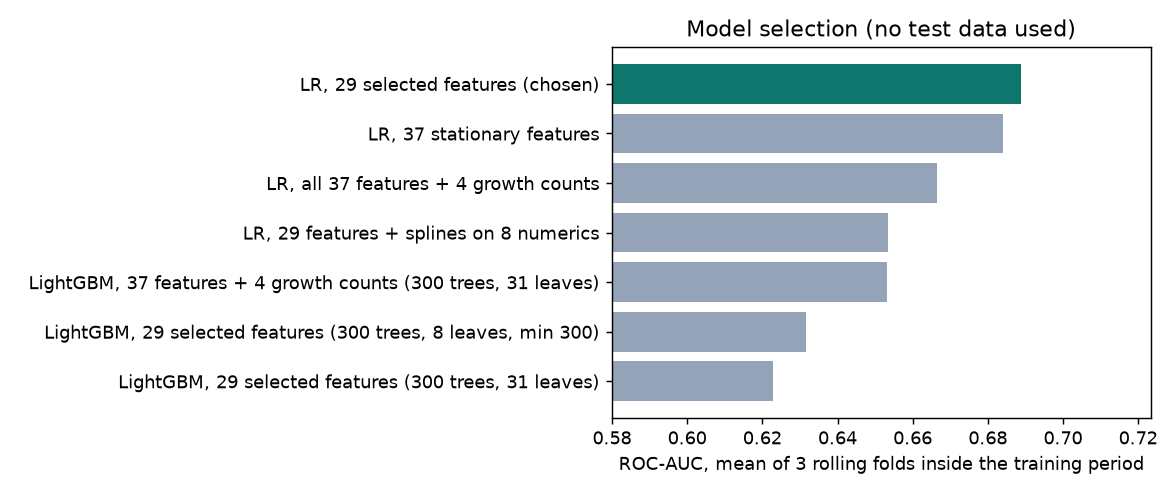

In [6]:
cv = pd.read_csv("reports/cv_model_selection.csv"); display(cv.round(4))
show("09_cv_model_selection.png", 760)

**How to read this.** The linear model wins in **every fold**. Two lessons:

- Replacing four *growth-trending counts* (cumulative seller order counts, platform order volume) with **scale-free ratios** improved the linear model (0.667 to 0.684). Counts that grow with the business act like a calendar clock; a flexible model can memorise "the volume was high in the November spike" and then fail on a later period.
- Gradient boosting lost to the regularised linear model (0.62 to 0.65 vs 0.689). With few late orders (about 2,500 for training) and regime-driven lateness, trees memorise episodes. Smooth non-linear terms (splines) also hurt (0.653).

,dropped_group,n_features,cv_roc_auc,change_in_auc,change_in_ap_lift
0,promise_calendar,5,0.6232,-0.0609,-0.4306
1,geography,4,0.6519,-0.0322,-0.1622
2,system_lateness,3,0.6703,-0.0138,-0.0684
3,seller_history,6,0.6719,-0.0122,-0.1087
4,order_payment,8,0.6815,-0.0026,-0.0031
5,holidays,3,0.6816,-0.0025,-0.0116
6,weather,4,0.6825,-0.0016,-0.0225
7,route_history,1,0.6854,0.0013,0.0209
8,product,3,0.6879,0.0038,0.0256


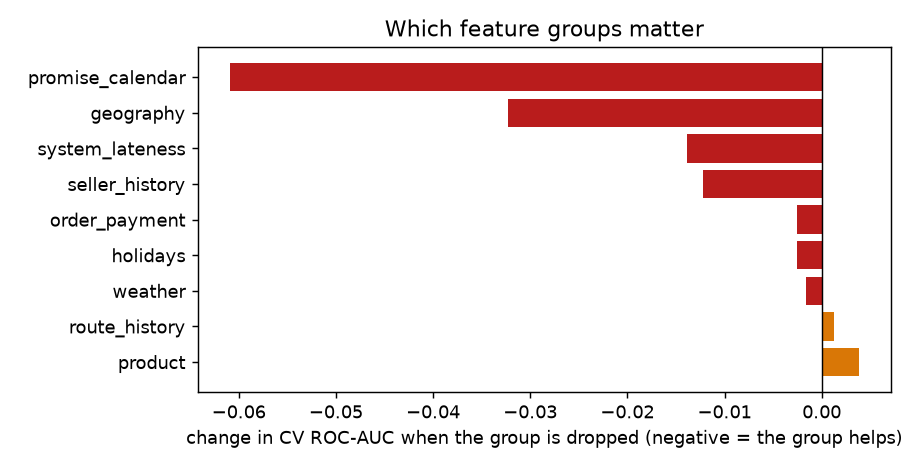


largest input drift, training to test (population stability index; above 0.25 = large):
holidays_in_window            1.9800
platform_late_rate_14d        1.4500
days_to_next_holiday          1.0600
seller_late_rate              0.8800
platform_load_ratio           0.8400
seller_mean_days_vs_promise   0.4900


In [7]:
ab = pd.read_csv("reports/cv_group_ablation.csv"); display(ab.round(4))
show("10_cv_group_ablation.png", 560)
drift = pd.Series(res["psi_train_to_test"]).sort_values(ascending=False).head(6)
print("\nlargest input drift, training to test (population stability index; above 0.25 = large):"); print(drift.round(2).to_string())

**How to read this.** Dropping the **promise and calendar** group costs 0.061 ROC-AUC, geography 0.032, system lateness 0.014, seller history 0.012. Groups whose removal did *not* hurt were dropped: **product** and **route history**, and **weather** (a tiny +0.002 that would also need a live weather feed when serving).
The input-drift table shows why flexible models struggle: several inputs (holiday windows, recent platform lateness, load) change enormously between training and test.

## 4. The final model and what it learned

A regularised logistic regression (`C = 0.1`) on 29 features: heavy-tailed numbers are log-transformed and standardised, categories are one-hot encoded. It is fitted on the training window only.

,column,feature,coef
37,cat__customer_state_MG,customer_state,-0.9610
30,cat__customer_state_AL,customer_state,0.8730
44,cat__customer_state_PR,customer_state,-0.7320
6,num__promised_days,promised_days,-0.5670
50,cat__customer_state_SE,customer_state,0.5250
51,cat__customer_state_SP,customer_state,-0.5220
41,cat__customer_state_PB,customer_state,0.5210
38,cat__customer_state_MS,customer_state,-0.5030
33,cat__customer_state_DF,customer_state,-0.4990
36,cat__customer_state_MA,customer_state,0.4980


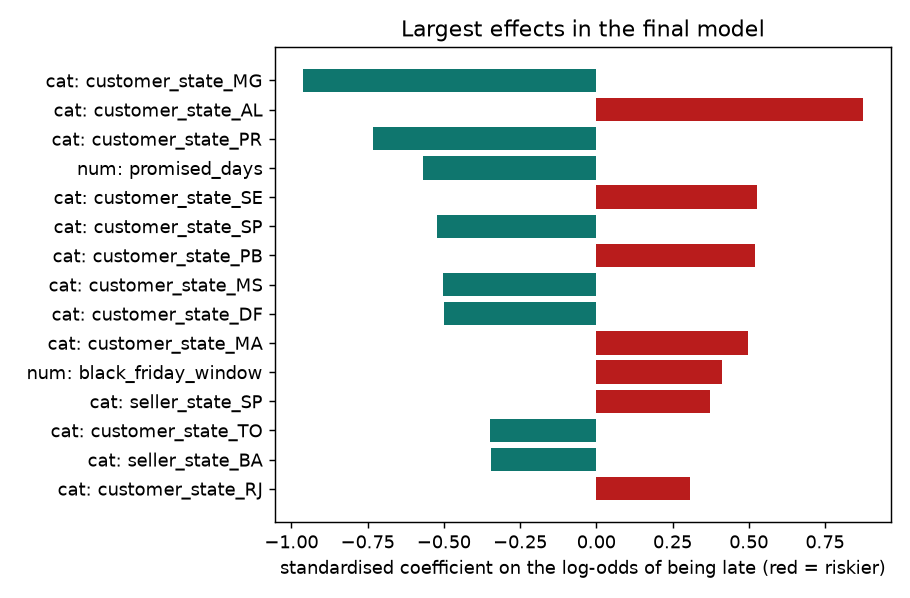

In [8]:
Xs = enc.transform(X, codes=False)
tr, va, te = masks["train"], masks["val"], masks["test"]
lr = fit_logreg(Xs[tr], y[tr], FINAL_FEATURES, C=C_REG)
from delivery.explain import coefficient_table, contributions
coef = coefficient_table(lr, FINAL_FEATURES)
display(coef.head(12).round(3))
show("13_coefficients.png", 600)

**How to read this.** Coefficients are on the log-odds scale, and numeric features are standardised so their sizes are comparable. The largest effects are the **customer's state** (some states are consistently safer or riskier) and the **promised days** (longer promises are safer). Because the model is linear, every prediction can be explained exactly: a feature's contribution is `coefficient x value`.

In [9]:
# Explain one real test order: contributions add up exactly to the model's own log-odds.
i = df.index[te][50]
c = contributions(lr, Xs.loc[[i]], FINAL_FEATURES).iloc[0]
p = lr.predict_proba(Xs.loc[[i], FINAL_FEATURES])[0, 1]
print(f"order {i}: predicted probability of being late = {p:.1%} | actually late: {bool(y[i])}")
print(c.reindex(c.abs().sort_values(ascending=False).index).head(6).round(3).to_string())
print("sum of contributions -> probability:", f"{1 / (1 + np.exp(-c.sum())):.1%}")

order 76842: predicted probability of being late = 12.4% | actually late: False
intercept                  -2.9570
promised_days              -0.9180
cust_state_late_rate_30d    0.6130
seller_state                0.3740
seller_late_rate_60d        0.3450
customer_state              0.3090
sum of contributions -> probability: 12.4%


## 5. One evaluation on the test window

**What and why.** The test window is evaluated once, for the selected model and for comparison models. Intervals are **95% bootstrap intervals** (1,000 resamples of orders). For comparing two models on the same orders, the right tool is the **paired difference** with its own interval, not two overlapping intervals judged by eye.

Metrics: **ROC-AUC** (does a late order get a higher score than an on-time one? 0.5 is chance), **PR-AUC** (precision/recall, sensitive to the 4% base rate), and **late orders in the riskiest 10%** (10% would be chance).

,model,ROC-AUC,PR-AUC,late orders in top 10%
0,Base rate (no model),"0.500 [0.500, 0.500]","0.042 [0.042, 0.042]",10.0%
1,Seller's historical late rate alone,"0.510 [0.489, 0.529]","0.045 [0.041, 0.050]",11.8%
2,Logistic regression: promise + calendar only,"0.703 [0.685, 0.720]","0.120 [0.104, 0.140]",31.0%
3,Logistic regression: promise + geography,"0.686 [0.671, 0.702]","0.077 [0.069, 0.089]",18.3%
4,Logistic regression: 29 selected features,"0.720 [0.705, 0.735]","0.100 [0.087, 0.117]",23.6%
5,"LightGBM (best by CV: 300 trees, 31 leaves)","0.645 [0.628, 0.660]","0.067 [0.060, 0.077]",16.4%


test base late rate: 4.24% | LightGBM over 5 seeds: AUC 0.652 +/- 0.007
selected model minus Seller's historical late rate alone            ROC-AUC +0.210 [+0.190, +0.229]
selected model minus Logistic regression: promise + calendar only   ROC-AUC +0.017 [-0.005, +0.039]
selected model minus Logistic regression: promise + geography       ROC-AUC +0.033 [+0.021, +0.046]
selected model minus LightGBM (best by CV: 300 trees, 31 leaves)    ROC-AUC +0.075 [+0.064, +0.087]


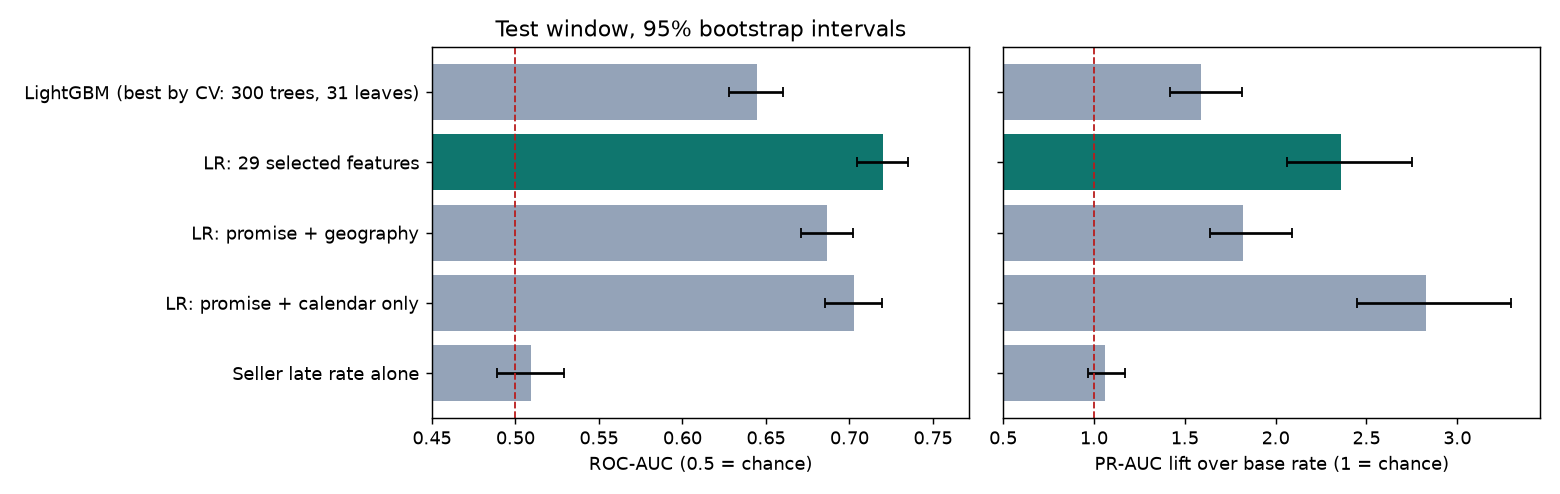

In [10]:
rows = []
for x in res["test_comparison"]:
    rows.append({"model": x["model"], "ROC-AUC": f"{x['roc_auc']:.3f} [{x['roc_auc_ci'][0]:.3f}, {x['roc_auc_ci'][1]:.3f}]",
                 "PR-AUC": f"{x['pr_auc']:.3f} [{x['pr_auc_ci'][0]:.3f}, {x['pr_auc_ci'][1]:.3f}]", "late orders in top 10%": f"{x['capture_top10']:.1%}"})
display(pd.DataFrame(rows))
print(f"test base late rate: {res['test_base_rate']:.2%} | LightGBM over 5 seeds: AUC {res['lightgbm_seed_spread']['roc_auc_mean']:.3f} +/- {res['lightgbm_seed_spread']['roc_auc_sd']:.3f}")
for name, d in res["paired_differences_vs_final"].items():
    print(f"selected model minus {name[:46]:46s} ROC-AUC {d['roc_auc'][0]:+.3f} [{d['roc_auc'][1]:+.3f}, {d['roc_auc'][2]:+.3f}]")
show("08_test_model_comparison.png", 900)

**How to read this.**

- The selected model reaches ROC-AUC **0.72** and catches **24%** of late orders in its riskiest 10% (a random 10% catches 10%). That is clearly better than chance, and **clearly modest**.
- It beats gradient boosting by **+0.075 ROC-AUC** (paired interval [+0.064, +0.087] excludes zero), as cross-validation predicted. The seller's historical late rate alone is at chance (0.51).
- A model with only **5 promise-and-calendar features** gets ROC-AUC 0.703, and even a higher PR-AUC (0.120 vs 0.100) and top-10% capture (31% vs 24%). Against the selected model the paired differences are **inconclusive**: ROC-AUC +0.017 [-0.005, +0.039] and PR-AUC -0.020 [-0.041, +0.002]. So the other 24 features add no *demonstrable* value on this test window. A fair summary: most of the usable signal is in how the promise was set.

In [11]:
ab = pd.DataFrame(res["test_ablation"]); display(ab.round(4))

,dropped_group,test_roc_auc,test_pr_auc,change_in_auc
0,promise_calendar,0.5779,0.0529,-0.1421
1,order_payment,0.7224,0.1045,0.0025
2,geography,0.6797,0.0802,-0.0403
3,seller_history,0.7103,0.0918,-0.0097
4,system_lateness,0.7064,0.0908,-0.0135
5,holidays,0.7107,0.0885,-0.0093


**How to read this.** On the test window, dropping the promise-and-calendar group costs 0.14 ROC-AUC and geography 0.04; the order/payment group is not helping (+0.002 when dropped), consistent with its small cross-validation effect.

## 6. Calibration and drift

**What and why.** A *calibrated* model's probabilities match observed frequencies (of orders scored 10%, about 10% are late). Calibration is fitted on a window and then used later, so it can only be as good as the stability of the world. Here the world is not stable.

,val_mean_pred,val_actual,test_mean_pred,test_actual,test_brier,test_ece
raw (trained on the training window),0.0675,0.1864,0.0466,0.0424,0.0396,0.0090
Platt scaling fitted on validation,0.1864,0.1864,0.1410,0.0424,0.0518,0.0986
isotonic fitted on validation,0.1864,0.1864,0.1387,0.0424,0.0523,0.0963


by cross-validation fold (calm / Black Friday / February spike): [(1, 'actual 3.9%', 'predicted 3.9%'), (2, 'actual 11.3%', 'predicted 3.3%'), (3, 'actual 11.5%', 'predicted 4.1%')]


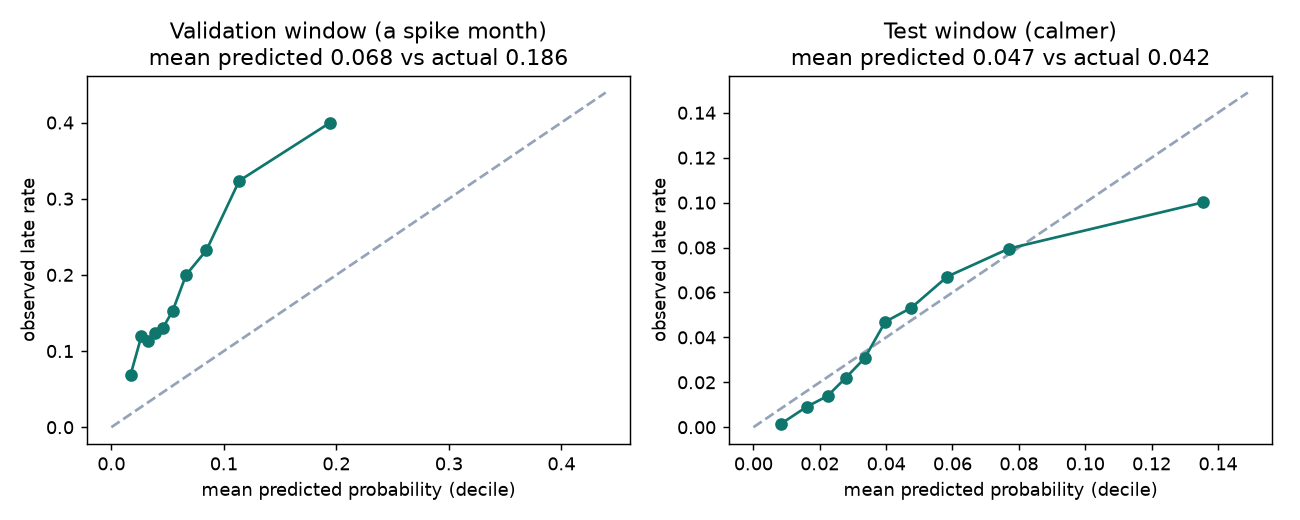

In [12]:
cal = pd.DataFrame(res["calibration"]).T[["val_mean_pred", "val_actual", "test_mean_pred", "test_actual", "test_brier", "test_ece"]]; display(cal.round(4))
print("by cross-validation fold (calm / Black Friday / February spike):",
      [(f["fold"], f"actual {f['actual_late_rate']:.1%}", f"predicted {f['mean_predicted']:.1%}") for f in res["calibration_by_cv_fold"]])
show("11_calibration.png", 820)

**How to read this.**

- The raw model's probabilities are well calibrated on the test period (predicted 4.7%, actual 4.2%) but **far too low in spike months** (it predicted 6.8% for March, when 18.6% were late). In the Black Friday and February cross-validation folds the same thing happens: the model's *level* does not adapt to the regime, while its *ordering* still works (higher scores really are riskier).
- A calibrator (Platt or isotonic) fitted on the March spike makes things **worse** on test: it predicts 14% when 4% are late, and Brier gets worse (0.040 to 0.052).
- The practical conclusion: use the **ranking** (a percentile among recent orders) for decisions, and treat absolute probabilities with care outside conditions like the training period.

,month,orders,late_rate,mean_pred,roc_auc
0,2018-05,2952,0.0740,0.0530,0.7520
1,2018-06,6096,0.0120,0.0300,0.7490
2,2018-07,6156,0.0340,0.0510,0.6660
3,2018-08,5670,0.0680,0.0570,0.6100


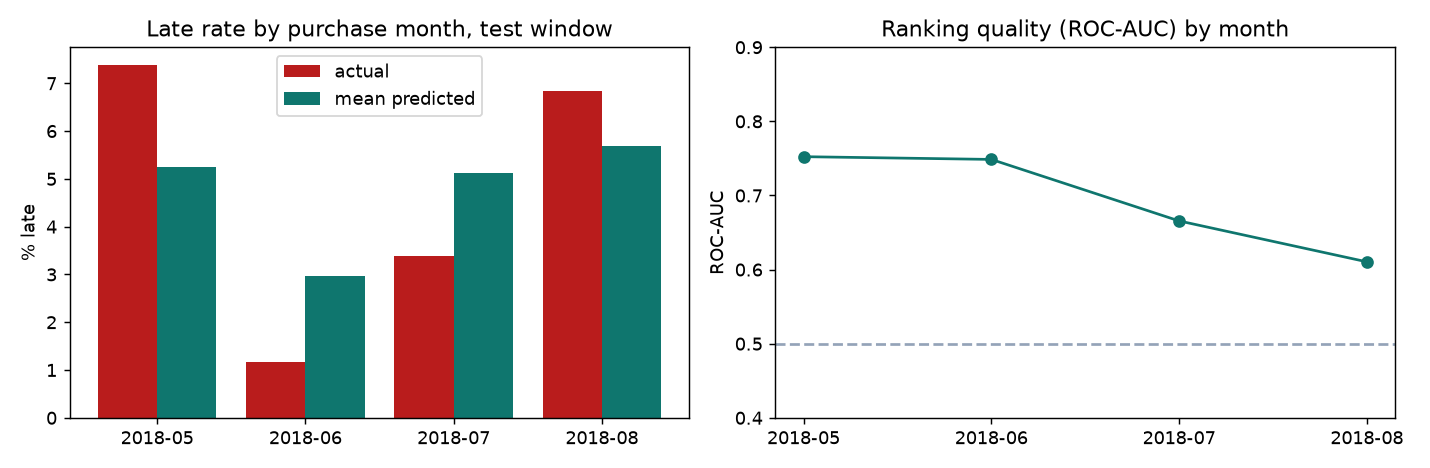

In [13]:
m = pd.DataFrame(res["test_by_month"]); display(m.round(3))
show("12_monthly_behaviour.png", 900)

**How to read this.** Ranking quality **decays**: ROC-AUC is 0.75 in May and June, 0.67 in July and 0.61 in August. This is a real effect, not an artifact of the truncated end of the data (checked: the excluded tail is only 3% of the test window and scores 0.75). The practical meaning is a **retraining cadence**: monitor weekly AUC and retrain regularly on orders old enough to have resolved.

## 7. Would acting on the predictions pay?

**What and why.** A prediction is only useful if it changes a decision. Suppose flagging an order triggers an **intervention** that costs 1 unit and prevents the lateness with probability *s*; a late order that is not prevented costs *L* units. Flagging an order is worthwhile only when its chance of being late exceeds the **break-even precision** `1 / (s x L)`.

,L,success,flagged,precision,break_even,saving
0,5,0.5000,2%,16.5%,40.0%,-5.5%
1,5,0.5000,10%,10.0%,40.0%,-35.4%
2,10,0.5000,2%,16.5%,20.0%,-0.8%
3,10,0.5000,10%,10.0%,20.0%,-11.8%
4,20,0.5000,2%,16.5%,10.0%,+1.5%
5,20,0.5000,10%,10.0%,10.0%,+0.0%
6,40,0.5000,2%,16.5%,5.0%,+2.7%
7,40,0.5000,10%,10.0%,5.0%,+5.9%


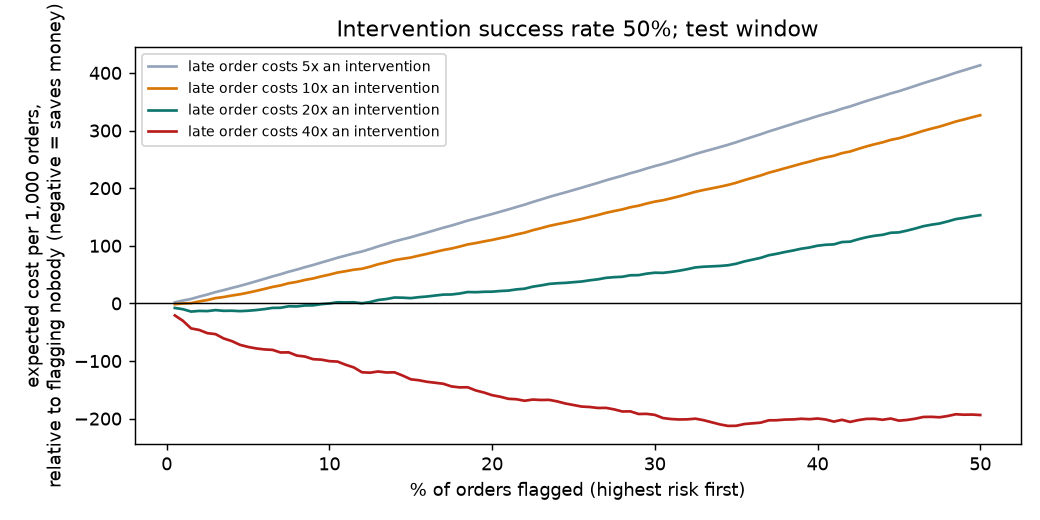

In [14]:
def policy(L, s, share):
    g = pd.DataFrame(res["gain_curve"]); r = g.iloc[(g.share - share).abs().argmin()]
    base = res["test_base_rate"]
    cost = r.share + L * (base - s * r.recall * base); never = L * base
    return dict(L=L, success=s, flagged=f"{r.share:.0%}", precision=f"{r.precision:.1%}", break_even=f"{1 / (s * L):.1%}", saving=f"{(never - cost) / never:+.1%}")
display(pd.DataFrame([policy(L, 0.5, q) for L in (5, 10, 20, 40) for q in (0.02, 0.10)]))
show("14_cost_vs_flagged_share.png", 760)

**How to read this.** The model's precision is about **20% for its riskiest 1%, 17% for the riskiest 2%, 13% for the riskiest 5% and 10% for the riskiest 10%**. So, with an intervention that works half the time:

- If a late order costs **10x** an intervention, break-even is 20% precision, and flagging saves essentially **nothing** (+0.3% at best).
- At **20x**, break-even is 10%, and a small selective policy saves under 2%.
- At **40x**, flagging about a third of orders saves about **12%** of the expected cost.

With a more effective intervention (80% success), the same cost ratios give about +2%, +12% and +36%. (The best flag share in this analysis is chosen with test data, so these savings are slightly optimistic; the theory-based probability threshold gives nearly the same.)

So an ROC-AUC of 0.72 is only valuable when interventions are *cheap relative to the cost of a late order* (a free change to the delivery estimate shown to the customer, for example). This is the most decision-relevant finding of the project, and it is easy to miss if you stop at AUC.

## 8. Serving: from model to API

**What and why.** The model, its encoders and small lookup tables are saved in `models/` (about 0.8 MB in total). `delivery.serve.Predictor` builds the features for **one** order: calendar facts from the dates, distance from zip-code centroids, and seller/state/platform history from lookup tables "as of" a snapshot date.
The risk is *training/serving skew*: the batch pipeline computes history "as of each order's purchase time", while serving looks up "as of now". `tests/test_serving.py` checks that the two agree for real orders across all 29 features (and fails if one formula is changed by a single unit; this was verified by deliberately breaking one).

In [15]:
from delivery.serve import Predictor
pred = Predictor()
s = json.load(open("models/lookups/sample_orders.json"))[3]
order = {k: v for k, v in s.items() if not k.startswith("actual") and k != "score_at_purchase_time"}
out = pred.predict(order, top_k=4)
print({k: out[k] for k in ("late_probability", "risk_percentile", "flag", "stats_as_of")})
for f in out["top_factors"]:
    print(f"  {f['direction']:11s} {f['label']:48s} = {f['value']}")
print("what actually happened:", "late" if s["actual_late"] else "on time")

{'late_probability': 0.0743, 'risk_percentile': 84.2, 'flag': False, 'stats_as_of': '2018-08-22 00:00:00'}
  raises risk days promised                                    = 17
  lowers risk customer state                                   = SP
  raises risk freight cost                                     = 119.46
  raises risk seller's typical delivery time                   = 14.275862068965518
what actually happened: on time


**How to read this.** The response carries the probability, a **risk percentile** among recent orders, a flag (default: the riskiest 10%), the top contributing factors, and warnings (for example for a seller never seen before). The same logic is exposed by a **FastAPI** service (`app/main.py`, run in Docker) and by the **Streamlit** app (`app/streamlit_app.py`).

In [16]:
print("""Run the API locally:     uvicorn app.main:app --port 8000      (PYTHONPATH=src)
Or in Docker:            docker build -t delivery-risk-api .  &&  docker run -p 8000:8000 delivery-risk-api
Example request:         curl -X POST localhost:8000/predict -H 'content-type: application/json' -d @order.json
Interactive docs:        http://localhost:8000/docs""")

Run the API locally:     uvicorn app.main:app --port 8000      (PYTHONPATH=src)
Or in Docker:            docker build -t delivery-risk-api .  &&  docker run -p 8000:8000 delivery-risk-api
Example request:         curl -X POST localhost:8000/predict -H 'content-type: application/json' -d @order.json
Interactive docs:        http://localhost:8000/docs


## 9. Summary and what not to claim

**Safe to say**
- The model predicts late deliveries at purchase time with ROC-AUC **0.72** (95% interval 0.70 to 0.74) on 20,874 later orders, and catches **24%** of late orders in its riskiest 10%. A regularised linear model beat gradient boosting (+0.075 AUC), chosen by rolling cross-validation rather than test-set tuning.
- The evaluation is time-based with maturity gaps, a unit-tested leakage check, bootstrap intervals, and a sensitivity check on the data's truncated tail.
- Rainfall, collected from a public API, adds almost nothing once promise, geography and recent system lateness are known. Seller lateness is concentrated within a period but not persistent across periods.
- Probabilities are regime-dependent and ranking quality decays over months, so decisions should use percentile flags and the model needs a retraining schedule.
- Acting on the flags saves essentially nothing when a late order costs 10x an intervention (50% success rate); it saves about 12% at 40x, or at 20x with an 80% success rate.

**Do not say**
- That it would reduce late deliveries or cost in production (no intervention was ever tried; the cost numbers are assumptions).
- That the probabilities are "calibrated" in general, or that LightGBM "can't" do better (a few reasonable configurations lost; tuning more might help).
- Anything about India, Flipkart or Meesho: the data is a Brazilian marketplace from 2016 to 2018.
- That weather "doesn't matter": it adds little *given the other features in this data*.

**Where things live**

| What | File |
|---|---|
| data collection (Olist, holidays, weather) | `src/delivery/collect.py` |
| order table and label | `src/delivery/data.py` |
| features and leak-free history | `src/delivery/features.py`, `src/delivery/history.py` |
| time splits and gaps | `src/delivery/split.py`, `src/delivery/config.py` |
| models, calibration, metrics, cost logic | `src/delivery/modeling.py` |
| the whole run | `src/delivery/pipeline.py` |
| serving | `src/delivery/serve.py`, `app/main.py`, `app/streamlit_app.py`, `Dockerfile` |
| tests | `tests/` (20) |

**Exercises**
1. Change `MATURITY_DAYS` handling: train on orders purchased up to 15 days before the model date instead of 45. How does the training late rate change, and why?
2. In section 3, add the weather group back and re-run the cross-validation. Is the change larger than the fold-to-fold variation?
3. In section 7, find the cost ratio at which flagging the riskiest 10% first becomes profitable.
4. Why does a calibrator fitted on March fail on May to August, and what would a better recalibration scheme look like?